# ML Practical: Bank Customer Churn Prediction Using ANN

**Objective:** Build a neural-network classifier to predict whether a bank customer will leave the bank.

- `Exited = 0`: Customer stays
- `Exited = 1`: Customer leaves

Dataset file: `Churn_Modelling.csv`

Run the cells in order. If TensorFlow is not installed, run the installation cell first.


In [3]:
# Install required libraries if needed
%pip install tensorflow pandas numpy matplotlib seaborn scikit-learn


   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/384.1 MB 207.6 kB/s eta 0:30:48
   ---------------------------------------- 0.5/384.1 MB 207.6 kB/s eta 0:30:48
   ---------------------------------------- 0.5/384.1 MB 20

Could not find platform independent libraries <prefix>
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'c:\\Users\\ayaan khan\\OneDrive\\Desktop\\ML Practicals\\Lib\\site-packages\\tensorflow\\python\\_pywrap_tensorflow_common.dll'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached tensorflow-2.22.0rc0-cp314-cp314-win_amd64.whl.metadata (4.6 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.2-cp314-cp314-win_amd64.whl.metadata (7.7 kB)
  Using cached grpcio-1.85.1-cp314-cp314-win_amd64.whl.metadata (3.9 kB)
  Using cached keras_nightly-3.16.0.dev2026103103-py3-none-any.whl.metadata (6.6 

Could not find platform independent libraries <prefix>
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# 1. Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping


In [5]:
# 2. Read the dataset

df = pd.read_csv("Churn_Modelling.csv")

print("FIRST FIVE RECORDS:")
display(df.head())

print("\nDATASET SHAPE:")
print(df.shape)

print("\nDATASET INFORMATION:")
df.info()

print("\nMISSING VALUES:")
print(df.isnull().sum().sum())

print("\nTARGET DISTRIBUTION:")
print(df["Exited"].value_counts())


FIRST FIVE RECORDS:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



DATASET SHAPE:
(10000, 14)

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB

MISSING VALUES:
0

TARGET DISTRIBUTION:
Exited
0    7963
1

In [6]:
# 3. Data preprocessing

# Remove unnecessary identifier columns
df = df.drop(
    columns=["RowNumber", "CustomerId", "Surname"],
    errors="ignore"
)

# Remove rows with missing values, if any
df = df.dropna()

# Separate features and target
X = df.drop(columns=["Exited"])
y = df["Exited"]

# Convert categorical columns into numerical columns
X = pd.get_dummies(
    X,
    columns=["Geography", "Gender"],
    drop_first=True,
    dtype=int
)

print("FEATURES AFTER PREPROCESSING:")
display(X.head())

print("\nFEATURE SHAPE:", X.shape)
print("TARGET SHAPE:", y.shape)


FEATURES AFTER PREPROCESSING:


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0



FEATURE SHAPE: (10000, 11)
TARGET SHAPE: (10000,)


In [7]:
# 4. Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAINING DATA SIZE:", X_train.shape)
print("TESTING DATA SIZE:", X_test.shape)


TRAINING DATA SIZE: (8000, 11)
TESTING DATA SIZE: (2000, 11)


In [8]:
# 5. Normalize the data

scaler = StandardScaler()

# Fit only on training data to prevent data leakage
X_train = scaler.fit_transform(X_train)

# Use the same scaler to transform test data
X_test = scaler.transform(X_test)

print("DATA NORMALIZATION COMPLETED!")


DATA NORMALIZATION COMPLETED!


In [9]:
# 6. Build the initial ANN model

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("INITIAL ANN MODEL:")
model.summary()


INITIAL ANN MODEL:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# 7. Train the initial ANN model

history_initial = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.20,
    verbose=1
)

print("INITIAL MODEL TRAINING COMPLETED!")


Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6445 - loss: 0.6407 - val_accuracy: 0.8000 - val_loss: 0.5188
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 981us/step - accuracy: 0.7952 - loss: 0.4843 - val_accuracy: 0.8000 - val_loss: 0.4554
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 963us/step - accuracy: 0.8072 - loss: 0.4344 - val_accuracy: 0.8344 - val_loss: 0.4112
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 960us/step - accuracy: 0.8308 - loss: 0.4004 - val_accuracy: 0.8413 - val_loss: 0.3868
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 975us/step - accuracy: 0.8366 - loss: 0.3832 - val_accuracy: 0.8506 - val_loss: 0.3713
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 973us/step - accuracy: 0.8423 - loss: 0.3724 - val_accuracy: 0.8550 - val_loss: 0.3609
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 986us/step - accuracy: 0.8472 - loss: 0.3653 - val_accuracy: 0.8569 - val_loss: 0.3542
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 951us/step - accuracy: 0.8506 - loss: 0.3605 - va

In [11]:
# 8. Build the improved ANN model

# Improvements:
# - More neurons in the first hidden layer
# - Additional hidden layer
# - Dropout to help reduce overfitting
# - Early stopping is applied during training in the next cell

improved_model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

improved_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("IMPROVED ANN MODEL:")
improved_model.summary()


IMPROVED ANN MODEL:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,057 (4.13 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# 9. Train the improved ANN model with Early Stopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = improved_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

print("IMPROVED MODEL TRAINING COMPLETED!")


Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7894 - loss: 0.5066 - val_accuracy: 0.8000 - val_loss: 0.4535
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7953 - loss: 0.4620 - val_accuracy: 0.8000 - val_loss: 0.4430
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7959 - loss: 0.4463 - val_accuracy: 0.8012 - val_loss: 0.4365
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7966 - loss: 0.4394 - val_accuracy: 0.8106 - val_loss: 0.4291
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8006 - loss: 0.4322 - val_accuracy: 0.8294 - val_loss: 0.4216
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8086 - loss: 0.4267 - val_accuracy: 0.8381 - val_loss: 0.4145
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8133 - loss: 0.4215 - val_accuracy: 0.8331 - val_loss: 0.4054
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8184 - loss: 0.4160 - val_accu

In [13]:
# 10. Predict test data

y_probability = improved_model.predict(X_test)

# Convert probabilities to binary classes (0 or 1)
y_pred = (y_probability >= 0.5).astype(int).ravel()

print("FIRST 10 PREDICTIONS:")
print(y_pred[:10])


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 855us/step
FIRST 10 PREDICTIONS:
[0 0 0 0 0 0 0 0 1 0]


In [14]:
# 11. Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("MODEL ACCURACY:")
print("Accuracy:", round(accuracy * 100, 2), "%")


MODEL ACCURACY:
Accuracy: 86.1 %


CONFUSION MATRIX:
[[1539   54]
 [ 224  183]]


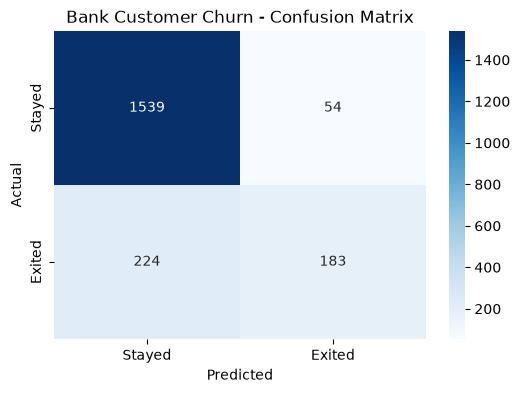

In [15]:
# 12. Generate and display the confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("CONFUSION MATRIX:")
print(cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Exited"],
    yticklabels=["Stayed", "Exited"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Bank Customer Churn - Confusion Matrix")
plt.show()


In [16]:
# 13. Classification report

print("CLASSIFICATION REPORT:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Stayed", "Exited"],
        zero_division=0
    )
)


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      Stayed       0.87      0.97      0.92      1593
      Exited       0.77      0.45      0.57       407

    accuracy                           0.86      2000
   macro avg       0.82      0.71      0.74      2000
weighted avg       0.85      0.86      0.85      2000



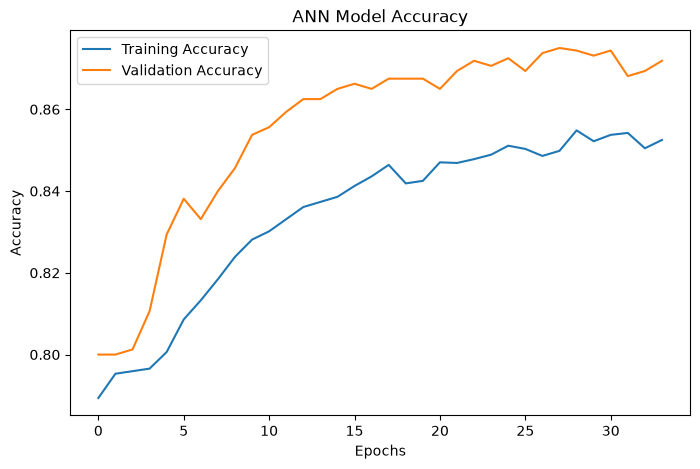

In [17]:
# 14. Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("ANN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


In [18]:
# 15. Final result

print("FINAL RESULT")
print("--------------------------------")
print("Bank Customer Churn Prediction Completed!")
print("Final Accuracy:", round(accuracy * 100, 2), "%")
print("\n0 = Customer will stay")
print("1 = Customer will leave")
print("\nPRACTICAL EXECUTED SUCCESSFULLY!")


FINAL RESULT
--------------------------------
Bank Customer Churn Prediction Completed!
Final Accuracy: 86.1 %

0 = Customer will stay
1 = Customer will leave

PRACTICAL EXECUTED SUCCESSFULLY!
